In [9]:
from th_ldv import DATA_PATH, DATA_LST
from th_ldv.dataIo import load_lda_point
from matplotlib import pyplot as plt

In [3]:
DATA_LST

,Unnamed: 0,file_path,sample_time,dt_max,length,x,y,z
0,0,raw/LDA/2024_11_26/TH_F0USY25_Zhigh_lpm_000_40...,299.972083,190.18345,25693,1017.0,25.0,65.0
1,1,raw/LDA/2024_11_26/TH_F0USY25_Zhigh_lpm_000_40...,299.980872,230.45600,27691,1017.0,25.0,70.0
2,2,raw/LDA/2024_11_26/TH_F0USY25_Zhigh_lpm_000_40...,299.982132,145.30200,28380,1017.0,25.0,75.0
3,3,raw/LDA/2024_11_26/TH_F0USY25_Zhigh_lpm_000_40...,299.997729,148.11380,30489,1017.0,25.0,80.0
4,4,raw/LDA/2024_11_26/TH_F0USY25_Zhigh_lpm_000_40...,299.988605,169.04115,32309,1017.0,25.0,85.0
...,...,...,...,...,...,...,...,...
364,364,raw/LDA/2024_12_01/TH_F1USY-25_Zlow_lpm_000_40...,299.963098,160.00415,61490,1062.0,-25.0,140.0
365,365,raw/LDA/2024_12_01/TH_F1USY-25_Zlow_lpm_000_40...,299.993584,110.59855,63430,1062.0,-25.0,150.0
366,366,raw/LDA/2024_12_01/TH_F1USY-25_Zlow_lpm_000_40...,299.991905,112.79665,64070,1062.0,-25.0,160.0
367,367,raw/LDA/2024_12_01/TH_F1USY-25_Zlow_lpm_000_40...,299.984538,83.29055,68989,1062.0,-25.0,170.0


In [7]:
path = DATA_PATH / DATA_LST.iloc[0]['file_path']
data = load_lda_point(path)

In [8]:
data

<xarray.Dataset> Size: 822kB
Dimensions:       (time: 25693)
Coordinates:
  * time          (time) float64 206kB 0.0 14.09 41.13 ... 2.999e+05 3e+05 3e+05
    x             float64 8B 1.017e+03
    y             float64 8B 25.0
    z             float64 8B 65.0
Data variables:
    w             (time) float64 206kB 1.64 -0.16 1.79 -0.84 ... 0.61 -0.61 1.0
    u             (time) float64 206kB 0.22 -0.75 -0.39 ... -1.51 -0.86 -1.0
    transit_time  (time) float64 206kB 22.2 32.9 23.5 10.2 ... 36.3 34.1 33.7
Attributes:
    date:     0

(0.0, 10000.0)

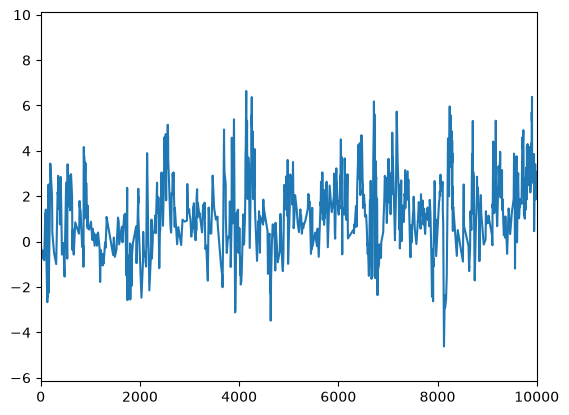

In [13]:
fig, ax =plt.subplots()
ax.plot(data['time'], data['u'])
ax.set_xlim(0,10000)

In [16]:
data.turb.calculate_product("u'w'", weights = data.transit_time)

<xarray.DataArray "u'w'" (time: 25693)> Size: 206kB
array([-0.73699136,  0.64988989, -1.7444004 , ..., -0.76923021,
        1.42551896, -1.28201252], shape=(25693,))
Coordinates:
  * time     (time) float64 206kB 0.0 14.09 41.13 ... 2.999e+05 3e+05 3e+05
    x        float64 8B 1.017e+03
    y        float64 8B 25.0
    z        float64 8B 65.0

In [21]:
data = data.turb.calc_all_products(weights = data.transit_time)

In [22]:
data.turb.calc_quadrant_contribution(weights = data.transit_time)

<xarray.Dataset> Size: 248B
Dimensions:       (quadrant: 4)
Coordinates:
    quadrantime   (quadrant) int64 32B 1 2 3 4
    x             float64 8B 1.017e+03
    y             float64 8B 25.0
    z             float64 8B 65.0
Dimensions without coordinates: quadrant
Data variables:
    w             (quadrant) float64 32B 0.193 0.3649 -0.1035 -0.1835
    u             (quadrant) float64 32B 0.3132 -0.04632 -0.03279 0.5242
    transit_time  (quadrant) float64 32B 4.771 14.61 16.61 5.733
    u'u'          (quadrant) float64 32B 0.2583 0.4326 0.2764 0.7504
    u'w'          (quadrant) float64 32B 0.1216 -0.2674 0.1521 -0.404
    w'w'          (quadrant) float64 32B 0.1683 0.3407 0.2363 0.4403
Attributes:
    date:     0